![Banner](./img/AI_Special_Program_Banner.jpg)

# Exercises for Ensemble Learning
---
The exercises are strongly oriented towards the lecture material and can often be solved with minor adaptations of the same.

> **Attention:** The tasks marked as optional do not have to be completed. If you want or are interested, you can sumbmit them.

## Data preparation

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd

In this exercise we want to deal with glass: [Glass Identification Data Set](http://archive.ics.uci.edu/ml/datasets/Glass+Identification). This is about the classification of different types of glass based on the oxide compounds.

<img src="./img/glass_dataset_metadata.png" width="600">

| Variable Name   | Role    | Type        | Description        | Units                                  | Missing Values |
|-----------------|---------|-------------|--------------------|----------------------------------------|----------------|
| Id_number       | ID      | Integer     |                    |                                        | no             |
| RI              | Feature | Continuous  | Refractive index   |                                        | no             |
| Na              | Feature | Continuous  | Sodium             | Weight percent in corresponding oxide  | no             |
| Mg              | Feature | Continuous  | Magnesium          | Weight percent in corresponding oxide  | no             |
| Al              | Feature | Continuous  | Aluminum           | Weight percent in corresponding oxide  | no             |
| Si              | Feature | Continuous  | Silicon            | Weight percent in corresponding oxide  | no             |
| K               | Feature | Continuous  | Potassium          | Weight percent in corresponding oxide  | no             |
| Ca              | Feature | Continuous  | Calcium            | Weight percent in corresponding oxide  | no             |
| Ba              | Feature | Continuous  | Barium             | Weight percent in corresponding oxide  | no             |
| Fe              | Feature | Continuous  | Iron               | Weight percent in corresponding oxide  | no             |
| Type_of_glass   | Target  | Categorical |                    |                                        | no             |

In [2]:
col_names = ['Id', 'RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Target']
df = pd.read_csv('http://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data', names=col_names)
df.head()

,Id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Target
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Remove the ID column (is only a surrogate key):

In [3]:
df.drop('Id', axis=1, inplace=True)

The data contains 7 different classes, which can be roughly divided into window glass and non-window glass. Since we want to consider a binary classification, we assign the superordinate categories accordingly:

In [4]:
map_target = {1 : 0, # building_windows_float_processed
              2 : 0, # building_windows_non_float_processed
              3 : 0, # vehicle_windows_float_processed
              4 : 0, # vehicle_windows_non_float_processed (none in this database)
              5 : 1, # containers
              6 : 1, # tableware
              7 : 1} # headlamps

In [5]:
df['Target'] = df['Target'].map(map_target)

Derive the feature matrix `X` and label vector `y`:

In [6]:
y = df.pop('Target')
X = df.copy()

Division of the data into training and test data. In addition, scaling of the data.

**Note:** We do this exactly in this order to avoid *data leakage*. You can find more information on this in this [article by Jason Brownlee](https://machinelearningmastery.com/data-leakage-machine-learning/) and this [blog post by Sebastian Raschka](https://sebastianraschka.com/faq/docs/scale-training-test.html).

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split # sklearn.cross_validation has been superseded

X_train, X_test, y_train, y_test =\
       train_test_split(X, y, 
                        test_size=0.25, 
                        stratify=y,
                        random_state=1)

sc = StandardScaler()
sc.fit(X_train)

X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)

In [8]:
print(f'There are {X_train_std.shape[0]} training data and {X_test_std.shape[0]} test data.')

There are 160 training data and 54 test data.


<h1 style="color:blue">Exercises</h1>

---

<h2 style="color:blue">Task 1 - Select the most important features</h2>

In this exercise, you will use a **decision tree classifier** to identify which features are most relevant for a classification task.  
While you are already familiar with **pipelines in scikit-learn**, this exercise introduces the concept of **feature importance**.

### What is feature importance?
Some models, such as decision trees, can estimate how **important** each feature is for making predictions.  
The attribute `feature_importances_` assigns a numerical value to each feature:
- higher values indicate that a feature contributes more to the model’s decisions,
- values close to zero indicate little or no contribution.

### Tasks
* Train a decision tree classifier using the configuration provided below.
* After training, access the attribute `feature_importances_` of the decision tree.
* **Select the two most important features** based on these importance values.
* Answer the following questions:
  - Which two features were selected?
  - List **all features** together with their feature importances.
  - Which features do **not** contribute (or contribute very little) to the classification?
* Create new feature matrices containing only the selected features and save them as:
  - `X_train_rel`
  - `X_test_rel`  
  These reduced feature sets will be used in later exercises.

### Further reading
You can read more about feature importance in scikit-learn here:  
https://scikit-learn.org/stable/modules/ensemble.html#feature-importance


In [9]:
from sklearn.tree import DecisionTreeClassifier

clf_dt = DecisionTreeClassifier(max_depth=3, 
                                criterion='gini', 
                                random_state=0)

In [10]:
# Your answer
import warnings
warnings.filterwarnings("ignore")

# Train the decision tree on the standardised training data
clf_dt.fit(X_train_std, y_train)

# Pair each feature with its importance and sort them in descending order
feature_names = X.columns
importances = pd.Series(clf_dt.feature_importances_,
                        index=feature_names).sort_values(ascending=False)

print("Feature importances (sorted):")
print(importances.to_string())

# The two most important features
top2 = importances.index[:2].tolist()
top2_idx = [feature_names.get_loc(f) for f in top2]
print(f"\nThe two most important features are: '{top2[0]}' and '{top2[1]}'.")

# Features that do not contribute to the classification
zero_feats = importances[importances == 0].index.tolist()
print(f"Features that do NOT contribute (importance = 0): {zero_feats}")

# Reduced feature matrices containing only the two selected features (used in later tasks)
X_train_rel = X_train_std[:, top2_idx]
X_test_rel  = X_test_std[:, top2_idx]
print(f"\nReduced feature sets created -> X_train_rel: {X_train_rel.shape}, X_test_rel: {X_test_rel.shape}")

Feature importances (sorted):
Mg    0.673714
RI    0.183259
Ba    0.069005
Na    0.057467
Al    0.016556
Si    0.000000
K     0.000000
Ca    0.000000
Fe    0.000000

The two most important features are: 'Mg' and 'RI'.
Features that do NOT contribute (importance = 0): ['Si', 'K', 'Ca', 'Fe']

Reduced feature sets created -> X_train_rel: (160, 2), X_test_rel: (54, 2)


<h2 style="color:blue">Task 2 - Create and cross-validate a voting classifier</h2>

1. Use the following base classifiers:
    1. *Perceptron*, with a maximum of 50 iterations, a tolerance of $10^{-3}$ and `random_state=0`
    2. [*Gaussian Naive Bayes*](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html) with the default settings
    3. *Logistic regression* with the default settings (`random_state=0`)
2. Use Hard Voting
3. Since we are considering unevenly distributed classes here, you should use the [Balanced Accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#balanced-accuracy-score) and the F1 score as scoring criteria.

In [11]:
# Your answer
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score

# Base classifiers
clf_ppn = Perceptron(max_iter=50, tol=1e-3, random_state=0)  # 50 iterations, tol=10^-3
clf_nb  = GaussianNB()                                       # default settings
clf_lr  = LogisticRegression(random_state=0)                 # default settings

# Hard-voting ensemble of the three base classifiers
clf_vc = VotingClassifier(
    estimators=[('ppn', clf_ppn), ('nb', clf_nb), ('lr', clf_lr)],
    voting='hard')

clf_labels = ['Perceptron', 'Naive Bayes', 'Logistic Regression', 'Hard Voting']
all_clf    = [clf_ppn, clf_nb, clf_lr, clf_vc]

# The classes are unevenly distributed (122 vs. 38), so we score with balanced accuracy and F1
for metric in ['balanced_accuracy', 'f1']:
    print(f'10-fold cross validation [{metric}]:')
    for clf, label in zip(all_clf, clf_labels):
        scores = cross_val_score(estimator=clf, X=X_train_rel, y=y_train,
                                 cv=10, scoring=metric)
        print("  %-20s %0.3f (+/- %0.3f)" % (label, scores.mean(), scores.std()))
    print()

print("Hard voting matches the best base learner (logistic regression) and clearly beats the\n"
      "weakest one (naive Bayes) on both metrics. The ensemble therefore delivers a robust\n"
      "result without having to know in advance which single classifier will perform best.")

10-fold cross validation [balanced_accuracy]:
  Perceptron           0.854 (+/- 0.128)
  Naive Bayes          0.817 (+/- 0.159)
  Logistic Regression  0.863 (+/- 0.132)
  Hard Voting          0.863 (+/- 0.132)

10-fold cross validation [f1]:


  Perceptron           0.788 (+/- 0.195)
  Naive Bayes          0.741 (+/- 0.228)
  Logistic Regression  0.813 (+/- 0.204)


  Hard Voting          0.813 (+/- 0.204)

Hard voting matches the best base learner (logistic regression) and clearly beats the
weakest one (naive Bayes) on both metrics. The ensemble therefore delivers a robust
result without having to know in advance which single classifier will perform best.


<h2 style="color:blue">Task 3 - Plot the decision areas of the ensemble and the base classifiers</h2>

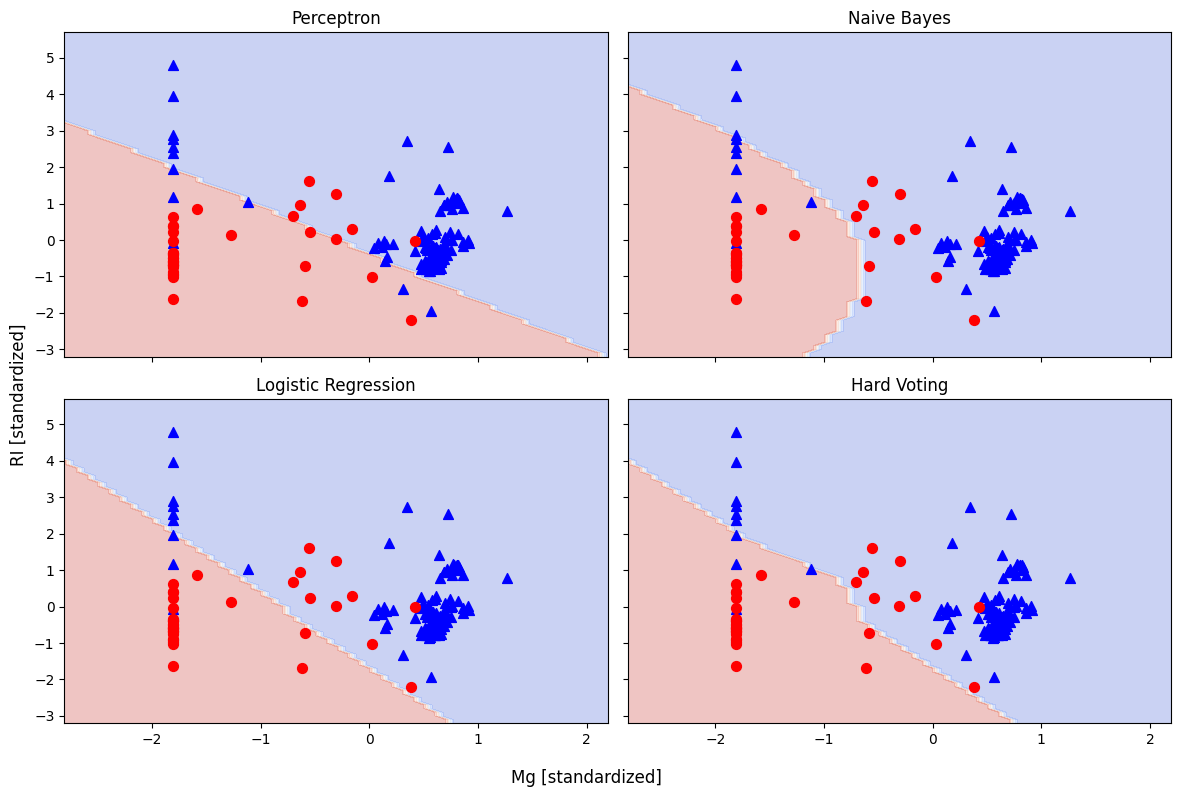

Perceptron and logistic regression give linear boundaries, Gaussian NB a smoother,
curved one. The hard-voting region is a hybrid dominated by the majority of the base
learners, which is why it looks almost identical to logistic regression here.


In [12]:
# Your answer
import numpy as np
from itertools import product

# Refit all four classifiers on the two selected features
for clf in all_clf:
    clf.fit(X_train_rel, y_train)

# Build a mesh grid over the (standardised) 2-D feature space
x_min, x_max = X_train_rel[:, 0].min() - 1, X_train_rel[:, 0].max() + 1
y_min, y_max = X_train_rel[:, 1].min() - 1, X_train_rel[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))
y_arr = y_train.values  # blue ^ = window glass (0), red o = non-window glass (1)

f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(12, 8))
for idx, clf, tt in zip(product([0, 1], [0, 1]), all_clf, clf_labels):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axarr[idx[0], idx[1]].contourf(xx, yy, Z, cmap='coolwarm', alpha=0.3)
    axarr[idx[0], idx[1]].scatter(X_train_rel[y_arr == 0, 0], X_train_rel[y_arr == 0, 1],
                                  c='blue', marker='^', s=50)
    axarr[idx[0], idx[1]].scatter(X_train_rel[y_arr == 1, 0], X_train_rel[y_arr == 1, 1],
                                  c='red', marker='o', s=50)
    axarr[idx[0], idx[1]].set_title(tt)

f.supxlabel(f"{top2[0]} [standardized]")
f.supylabel(f"{top2[1]} [standardized]")
plt.tight_layout()
plt.show()

print("Perceptron and logistic regression give linear boundaries, Gaussian NB a smoother,\n"
      "curved one. The hard-voting region is a hybrid dominated by the majority of the base\n"
      "learners, which is why it looks almost identical to logistic regression here.")

<h2 style="color:blue">Task 4 - Check which parameters can be adjusted for the voting classifier</h2>

**Hint**: There is a function, that lists all parameters of a model.

In [13]:
# Your answer
# get_params() lists every adjustable parameter of the voting classifier, including the
# parameters of the nested base estimators (prefixed with the estimator name, e.g. 'lr__C',
# 'ppn__alpha', 'nb__var_smoothing'). These are exactly the keys we can tune in a grid search.
clf_vc.get_params()

{'estimators': [('ppn', Perceptron(max_iter=50)),
  ('nb', GaussianNB()),
  ('lr', LogisticRegression(random_state=0))],
 'flatten_transform': True,
 'n_jobs': None,
 'verbose': False,
 'voting': 'hard',
 'weights': None,
 'ppn': Perceptron(max_iter=50),
 'nb': GaussianNB(),
 'lr': LogisticRegression(random_state=0),
 'ppn__alpha': 0.0001,
 'ppn__class_weight': None,
 'ppn__early_stopping': False,
 'ppn__eta0': 1.0,
 'ppn__fit_intercept': True,
 'ppn__l1_ratio': 0.15,
 'ppn__max_iter': 50,
 'ppn__n_iter_no_change': 5,
 'ppn__n_jobs': None,
 'ppn__penalty': None,
 'ppn__random_state': 0,
 'ppn__shuffle': True,
 'ppn__tol': 0.001,
 'ppn__validation_fraction': 0.1,
 'ppn__verbose': 0,
 'ppn__warm_start': False,
 'nb__priors': None,
 'nb__var_smoothing': 1e-09,
 'lr__C': 1.0,
 'lr__class_weight': None,
 'lr__dual': False,
 'lr__fit_intercept': True,
 'lr__intercept_scaling': 1,
 'lr__l1_ratio': 0.0,
 'lr__max_iter': 100,
 'lr__n_jobs': None,
 'lr__penalty': 'deprecated',
 'lr__random_state

<h2 style="color:blue">Task 5 - Use Grid Search to investigate the effect of using class weights</h2>

In this exercise, you will investigate how **class weighting** affects the performance of linear classifiers when dealing with imbalanced data.  
You will use **GridSearchCV** to systematically evaluate different settings.

### What are class weights?
In classification tasks with imbalanced classes, models may become biased toward the majority class.  
The `class_weight` parameter allows you to give **more importance to underrepresented classes** during training, which can improve performance on those classes.

Both the **Perceptron** and **Logistic Regression** in scikit-learn support class weighting.

### Tasks
* Use **GridSearchCV** to study the effect of the `class_weight` parameter for:
  - the *Perceptron*
  - *Logistic Regression*
* Compare at least the following settings:
  - no class weighting (default)
  - `class_weight="balanced"`
* Use **balanced accuracy** as the evaluation metric.
  - Balanced accuracy computes the average recall across classes and is well suited for imbalanced datasets.

### Further reading
You can learn more about class weighting and balanced accuracy here:
- Class weights in scikit-learn classifiers:  
  https://scikit-learn.org/stable/glossary.html#term-class-weight
- Balanced accuracy score:  
  https://scikit-learn.org/stable/modules/model_evaluation.html#balanced-accuracy-score

In [14]:
# Your answer
from sklearn.model_selection import GridSearchCV

# Both the Perceptron and Logistic Regression support the class_weight parameter.
# We compare no weighting (default) against the "balanced" mode using balanced accuracy.
weight_grid = {'class_weight': [None, 'balanced']}

for name, estimator in [('Perceptron', Perceptron(max_iter=50, tol=1e-3, random_state=0)),
                        ('Logistic Regression', LogisticRegression(random_state=0))]:
    gs = GridSearchCV(estimator, weight_grid, scoring='balanced_accuracy', cv=10)
    gs.fit(X_train_rel, y_train)

    print(f'{name}:')
    for params, mean, std in zip(gs.cv_results_['params'],
                                 gs.cv_results_['mean_test_score'],
                                 gs.cv_results_['std_test_score']):
        print("  class_weight=%-8s -> balanced accuracy %0.3f (+/- %0.3f)"
              % (str(params['class_weight']), mean, std))
    print(f"  best: {gs.best_params_} with {gs.best_score_:.3f}\n")

print("For both classifiers class_weight='balanced' improves the balanced accuracy: giving the\n"
      "under-represented non-window class more weight during training pushes the model to\n"
      "recognise the minority class instead of leaning towards the majority class.")

Perceptron:
  class_weight=None     -> balanced accuracy 0.854 (+/- 0.128)
  class_weight=balanced -> balanced accuracy 0.888 (+/- 0.131)
  best: {'class_weight': 'balanced'} with 0.888

Logistic Regression:
  class_weight=None     -> balanced accuracy 0.863 (+/- 0.132)
  class_weight=balanced -> balanced accuracy 0.892 (+/- 0.159)
  best: {'class_weight': 'balanced'} with 0.892

For both classifiers class_weight='balanced' improves the balanced accuracy: giving the
under-represented non-window class more weight during training pushes the model to
recognise the minority class instead of leaning towards the majority class.


<h2 style="color:blue">Task 6 - Train an Adaboost classifier with a perceptron as base classifier and a random forest and compare their respective accuracies (also with the base classifier)</h2>

* Use the *Balanced Accuracy* metric again
* Use the same settings for the perceptron as in task 2
* Since the perceptron does not provide class probabilities as output, you must set `algorithm='SAMME'` for Adaboost. Otherwise, use the same parameters as in the lecture material
* For the random forest, you can choose the same parameters as in the lecture materials

In [15]:
# Your answer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

# Base classifier: same perceptron settings as in task 2
base_ppn = Perceptron(max_iter=50, tol=1e-3, random_state=0)

# AdaBoost with the perceptron as base learner.
# The perceptron does not output class probabilities, so AdaBoost must use the discrete
# 'SAMME' algorithm. In scikit-learn 1.8 the 'algorithm' argument has been removed and SAMME
# is now the only (default) algorithm, so it no longer has to be passed explicitly.
ada = AdaBoostClassifier(estimator=base_ppn, n_estimators=500,
                         learning_rate=0.1, random_state=0)

# Random forest with the same parameters as in the lecture material
forest = RandomForestClassifier(criterion='entropy', n_estimators=10,
                                random_state=1, n_jobs=2)

print('Balanced accuracy (train / test):\n')
for name, clf in [('Perceptron (base)', base_ppn),
                  ('AdaBoost (perceptron)', ada),
                  ('Random Forest', forest)]:
    clf.fit(X_train_rel, y_train)
    tr = balanced_accuracy_score(y_train, clf.predict(X_train_rel))
    te = balanced_accuracy_score(y_test,  clf.predict(X_test_rel))
    print('  %-22s %.3f / %.3f' % (name, tr, te))

print("\nBoosting the perceptron barely helps: a linear base learner only produces linear\n"
      "boundaries in every round, so AdaBoost cannot build a more complex model and even\n"
      "overfits a little (higher train than test). The random forest generalises best, while\n"
      "the single perceptron already provides a strong baseline on these two features.")

Balanced accuracy (train / test):

  Perceptron (base)      0.892 / 0.872
  AdaBoost (perceptron)  0.893 / 0.834


  Random Forest          0.983 / 0.886



Boosting the perceptron barely helps: a linear base learner only produces linear
boundaries in every round, so AdaBoost cannot build a more complex model and even
overfits a little (higher train than test). The random forest generalises best, while
the single perceptron already provides a strong baseline on these two features.


<h2 style="color:blue">Task 7 - Plot the decision regions of the classifiers just created</h2>

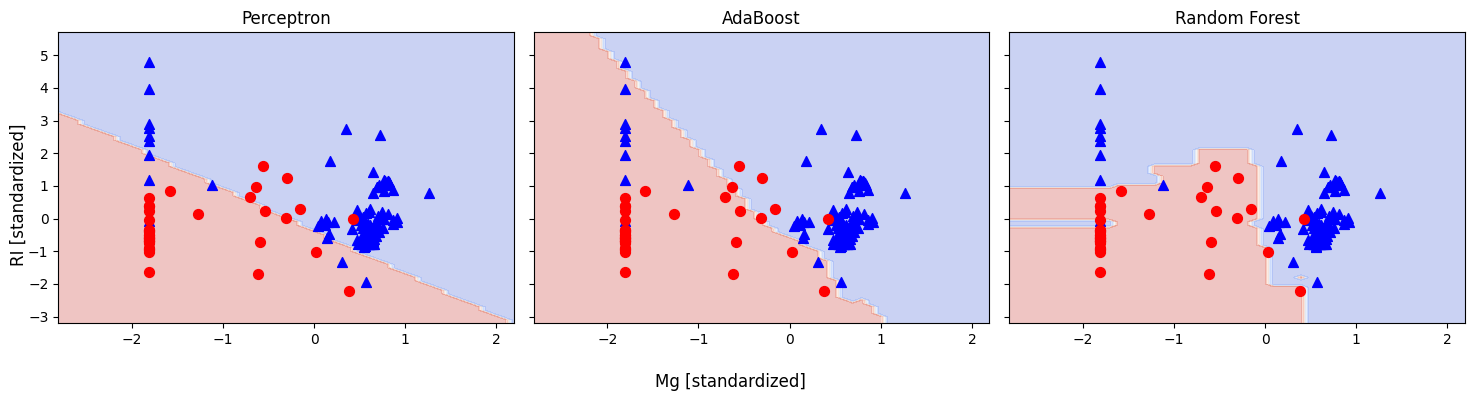

Perceptron and AdaBoost(perceptron) both produce (near-)linear boundaries - boosting a
linear base learner keeps the ensemble linear. The random forest, built from full
decision trees, carves out a non-linear, axis-aligned region that hugs the training data
far more tightly, which matches its higher training balanced accuracy in task 6.


In [16]:
# Your answer
import numpy as np

# Fresh mesh grid over the two selected features
x_min, x_max = X_train_rel[:, 0].min() - 1, X_train_rel[:, 0].max() + 1
y_min, y_max = X_train_rel[:, 1].min() - 1, X_train_rel[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))
y_arr = y_train.values  # blue ^ = window glass (0), red o = non-window glass (1)

f, axarr = plt.subplots(1, 3, sharex='col', sharey='row', figsize=(15, 4))
for idx, clf, tt in zip([0, 1, 2],
                        [base_ppn, ada, forest],
                        ['Perceptron', 'AdaBoost', 'Random Forest']):
    clf.fit(X_train_rel, y_train)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axarr[idx].contourf(xx, yy, Z, cmap='coolwarm', alpha=0.3)
    axarr[idx].scatter(X_train_rel[y_arr == 0, 0], X_train_rel[y_arr == 0, 1],
                       c='blue', marker='^', s=50)
    axarr[idx].scatter(X_train_rel[y_arr == 1, 0], X_train_rel[y_arr == 1, 1],
                       c='red', marker='o', s=50)
    axarr[idx].set_title(tt)

f.supxlabel(f"{top2[0]} [standardized]")
f.supylabel(f"{top2[1]} [standardized]")
plt.tight_layout()
plt.show()

print("Perceptron and AdaBoost(perceptron) both produce (near-)linear boundaries - boosting a\n"
      "linear base learner keeps the ensemble linear. The random forest, built from full\n"
      "decision trees, carves out a non-linear, axis-aligned region that hugs the training data\n"
      "far more tightly, which matches its higher training balanced accuracy in task 6.")